# Household Income-Distribution Projection — PBA 2050+

Disaggregates a **total household projection** into four **income quartiles** for the
Bay Area, by subregion and year.

Four OLS regressions (one per quartile) are estimated on **county-level census data**
(top-30 MSAs, ACS 2013) to relate the *share* of households in each income bin to a set
of demographic / labor-market covariates. The fitted coefficients are then applied to
**REMI's future projections** of those same covariates (by subregion) to move the income
distribution forward. Predicted shares are scaled to sum to 100%, indexed to an observed
2015 PUMS distribution, and multiplied by the total household projection from
[hhproj-clean.ipynb](hhproj-clean.ipynb).

**Notebook structure**
1. Imports
2. Configuration (paths, display)
3. Constants, mappings & scenario definitions
4. Helper functions
5. Extract — estimation data & observed income shares
6. Estimate — fit the four income-share regressions
7. Extract — REMI future covariates
8. Transform — assemble right-hand-side variable series
9. Project — apply models & multiply by household totals
10. Outputs — write CSV / Excel deliverables
11. QA — inspection charts


## Methodology

### Overview

The goal is to disaggregate a **regional total-household projection** (produced upstream by
[hhproj-clean.ipynb](hhproj-clean.ipynb)) into **four income quartiles** for each Bay Area
subregion and year. We do not model household incomes directly. Instead we model the
*share* of households falling into each income quartile as a function of a county's
demographic and labor-market composition, estimate that relationship on historical
census data, and then push it forward using REMI's projections of those same covariates.

The design intentionally mirrors REMI's own household-forecast method, but swaps in a
custom, Bay-Area-tuned specification for each quartile.

### Pipeline

```
county census data  ──▶  4 OLS models      (§5–6  Estimate)
                              │  coefficients
REMI future covariates ──────▶ predict shares per subregion-year   (§7–9  Project)
                              │  scale → index → renormalise
total household projection ──▶ multiply → households by income bin  (§9)
                              │
                              ▶ region tables, coefficients, UrbanSim controls (§10)
```

| Step | What happens | Where |
|------|--------------|-------|
| 1. Estimate | Fit 4 independent OLS models on county-level census data (top-30 MSAs, ACS 2013). Dependent variable *k* = PUMS-based share of households in income quartile *k*. | §5–6 |
| 2. Prepare future covariates | Pull the same covariates from REMI's future projections, by subregion and year (2015–2050). | §7–8 |
| 3. Predict | For each quartile, multiply coefficients by the future covariates and add the intercept → a raw predicted score. | §9 |
| 4. Scale | The four raw scores are **not** guaranteed to sum to 1, so rescale them to 100% within each subregion-year. | §9 |
| 5. Index | Re-anchor to the observed 2015 PUMS distribution: use only the *relative change* implied by the regression, not its absolute level (see "Indexing" below). | §9 |
| 6. Apply | Multiply the indexed shares by the total-household projection to get counts by income bin; concatenate observed 2010/2015 history in front. | §9 |

### Data sources

| Source | Role | Vintage / years | Loaded in |
|--------|------|-----------------|-----------|
| County-level census panel (`allyears_feb2020upd.csv`, `censusdata_occvars.csv`) | Training sample (RHS + dependent shares) | multi-decade; model uses `ACS2013` | §5 |
| MSA crosswalk (`msamappings_1990_2013.csv`) | Restrict estimation to counties in the largest 30 MSAs | 1990–2013 | §5 |
| PUMS regional income shares (`pums_remireg_income_shares_*_q1fix.xlsx`) | Base-year (2015) distribution + observed 2010/2015 counts | 2006–2018 | §5 |
| REMI raw output (population, labor, employment, income workbooks) | Future covariates by subregion | 2015–2050 | §7 |
| Total household projection (`proj_region_hh_sc_*`) | The control totals being disaggregated | sparse grid, interpolated to annual | §9 |
| SOC structure (`soc_structure_2010.xls`) | Map REMI occupation labels → detailed-occupation covariates | 2010 | §7 |

### Income quartiles

`inc_cat_1` (lowest) … `inc_cat_4` (highest) are defined on the PUMS household-income
distribution used to build the dependent variable. The `q1fix` files apply a correction to
the lowest bin (very-low-income / negative-income households are noisy in raw PUMS).

### Regression specifications

Each quartile has its own hand-picked specification (selected previously for fit and
plausibility). Covariates are shares/ratios so coefficients are interpretable as the
marginal effect of a one-unit (i.e. 0→100%) shift in composition.

| Bin | Covariates |
|-----|------------|
| 1 (low) | `cnty_to_us`, `msasize=='Above 1 million'`, `occ_det_officeadmin`, `occ_det_mgmt`, `ag_65p`, `Swhite_NH` |
| 2 | `SLF`, `cnty_to_us`, `division=='09'`, `occ_det_officeadmin`, `occ_det_mgmt`, `occ_det_hlthsup`, `Shispanic`, `Swhite_NH`, `ag_25_64` |
| 3 | `log(per_capita_inc)`, `ind_prof`, `SLF`, `Sother_NH`, `occ_det_foodprep`, `occ_det_hlthsup`, `occ_det_biz`, `msasize=='Above 1 million'`, `ag_65p`, `ag_25_64` |
| 4 (high) | `cnty_to_us`, `occ_det_mgmt`, `occ_det_community`, `log(per_capita_inc)`, `ag_25_64` |

The specification lives in one place — `model_rhs` in §6 — and the term names there must
match the covariate frames assembled in §8 / `build_param_to_var` in §9.

### The sum-to-one problem (key limitation)

The central methodological weakness is that **four independently estimated OLS equations
are not constrained to produce shares that sum to one.** Consequences:

- Raw predictions can sum to something other than 100% (and individual bins can in principle
  fall outside [0, 1]), so a post-hoc **rescale to 100%** (step 4) is required.
- Because the rescaling is applied after estimation, the estimated coefficients are not the
  "true" marginal effects on the *constrained* shares — cross-equation adding-up is ignored
  during fitting, which can bias the split and makes standard errors hard to interpret.
- The model is not expected to reproduce the observed base-year level, only its *direction of
  change*, which is why we index to 2015 (step 5) rather than trusting the fitted intercepts.

**Indexing (step 5).** For each subregion-bin we take the fitted, rescaled share trajectory,
divide by its 2015 value to get an index (2015 = 1.0), multiply the *observed* 2015 PUMS
share by that index, then renormalise the four bins back to 100%. This preserves the
regression's implied *trend* while anchoring the *level* to observed data.

### Candidate improvements (launching pad for future work)

Natural directions when revisiting this, roughly in increasing order of effort:

1. **Data / vintage refresh.** Point `EST_VINTAGE`, `N_TOP_MSAS`, and the input files in §2/§5
   at newer ACS vintages and re-fit. The estimation universe (top-30 MSAs) is a lever too.
2. **Specification search.** `model_rhs` is the single edit point; consider automated/
   penalised selection (LASSO/elastic-net) and multicollinearity checks across the
   overlapping occupation-share covariates.
3. **Functional form that respects the simplex** — the most principled fix for the sum-to-one
   issue. Options:
   - **Compositional regression**: model additive log-ratios (ALR/ILR) of the four shares,
     which live in unconstrained space, then invert back to shares (guaranteed to sum to 1).
   - **Multinomial / fractional multinomial logit**: model the shares jointly so they are
     bounded in (0, 1) and add up by construction.
   - **Seemingly Unrelated Regression (SUR)** with an adding-up constraint: keeps the linear
     interpretation while enforcing cross-equation consistency, removing the need for the
     ad-hoc rescale.
4. **Uncertainty.** None of the current outputs carry prediction intervals; a joint model
   (above) would let us propagate covariate and coefficient uncertainty into the bin counts.
5. **Validation.** Add back-testing against held-out vintages / observed post-2015 PUMS to
   quantify how much the indexing step is doing versus the regression itself.

The rest of the notebook is organised so each of these is a localised change: data in §2/§5,
specification in §6, covariate construction in §8, and the predict → scale → index → apply
logic isolated in the two functions in §9.


## 1 · Imports

In [1]:
import os
import re
import fnmatch
import pathlib
import logging
from datetime import datetime

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

## 2 · Configuration

In [2]:
# --- Display ---
pd.set_option('display.max_columns', 1800)
pd.set_option('display.width', 1800)
pd.options.display.float_format = '{:,.2f}'.format

# --- Plot style ---
sns.set(style='darkgrid')
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = [12, 7]

In [3]:
HOME_DIR = pathlib.Path.home()
BOX_DIR = HOME_DIR / "Library/CloudStorage/Box-Box" if os.name != "nt" else pathlib.Path('E:/Box') 


_REG = BOX_DIR / 'Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update'

INPUT_REMI_PATH     = _REG / 'REMI_raw_output'
INPUT_BASEDATA_PATH = _REG / 'household_forecast/base_data'
INPUT_MAPPINGS_PATH = _REG / 'mappings'

# Total household projections are produced by hhproj-clean.ipynb (output_v2).
# This notebook reads them here and writes its own income outputs to the same folder.
HH_PROJ_PATH = _REG / 'household_forecast/output_v2'
OUTPUT_PATH  = HH_PROJ_PATH
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# --- Optional: pin a specific household-projection file per scenario ---------
# By default each scenario auto-discovers the *newest* matching CSV in
# HH_PROJ_PATH/<scenario> (see resolve_hh_projection_path in §4). Add an entry here
# to use an exact file instead — handy for reproducible runs or comparing vintages.
# Values may be absolute, or relative to HH_PROJ_PATH. Scenarios omitted here keep
# the latest-file behaviour.
HH_PROJ_FILES = {
    # 'REMI31_NC1_RC1_FBP': 'REMI31_NC1_RC1_FBP/proj_region_hh_sc_REMI31_NC1_RC1_FBP_HR_Phased_eased_20260731_134718.csv',
}


## 3 · Constants, mappings & scenario definitions

In [4]:
# --- Year ranges & model settings ---
YEARS_1       = list(range(2010, 2051, 1))
YEARS_1_2015  = list(range(2015, 2051, 1))
YEARS_5       = list(range(2010, 2051, 5))
YEARS_5_2015  = list(range(2015, 2051, 5))

STARTYEAR   = 2015                       # base year the indexed shares re-anchor to
YEARS_COARSE = [0, 15, 25, 65, np.inf]   # age bins used for REMI age-share covariates
EST_VINTAGE = 'ACS2013'                  # census vintage used to fit the models
N_TOP_MSAS  = 30                         # estimation universe: counties in top-N MSAs

# --- Dependent variables (PUMS-based income-quartile shares) ---
depvar = {k: 'inc_cat_%s_pums' % k for k in range(1, 5)}

In [5]:
# --- REMI 2-digit SOC major group -> detailed occupation covariate ---
occ_det_soc_map = {
    '11-0000': 'occ_det_mgmt',        '13-0000': 'occ_det_biz',
    '15-0000': 'occ_det_comp',        '21-0000': 'occ_det_community',
    '23-0000': 'occ_det_lgl',         '31-0000': 'occ_det_hlthsup',
    '35-0000': 'occ_det_foodprep',    '43-0000': 'occ_det_officeadmin',
}

# --- REMI 2-digit NAICS industry -> census industry covariate ---
indus_to_census = pd.Series({
    'state and local government': 'ind_public', 'federal civilian': 'ind_public',
    'federal military': 'ind_public',
    'forestry, fishing, and related activities': 'ind_other', 'mining': 'ind_other',
    'utilities': 'ind_other', 'construction': 'ind_other', 'manufacturing': 'ind_other',
    'wholesale trade': 'ind_other', 'retail trade': 'ind_retail',
    'transportation and warehousing': 'ind_other', 'information': 'ind_prof',
    'finance and insurance': 'ind_prof', 'real estate and rental and leasing': 'ind_prof',
    'professional, scientific, and technical services': 'ind_prof',
    'management of companies and enterprises': 'ind_prof',
    'administrative and waste management services': 'ind_other',
    'administrative, support, waste management, and remediation services': 'ind_other',
    'educational services': 'ind_educ', 'educational services; private': 'ind_educ',
    'health care and social assistance': 'ind_health',
    'arts, entertainment, and recreation': 'ind_other',
    'accommodation and food services': 'ind_accom_food_svcs',
    'other services, except public administration': 'ind_other',
    'other services': 'ind_other', 'forestry, fishing, and hunting': 'ind_other',
    'other services (except public administration)': 'ind_other', 'farm': 'ind_other',
}).to_dict()

In [6]:
# --- Scenarios to project ---
scenarios = {
    'REMI31_NC0_RC0_BASE': 'REMI 3.1 Standard Regional Control',
    'REMI31_NC0_RC0_FBP':  'REMI 3.1 Native FBP',
    'REMI31_NC1_RC1_FBP':  'REMI 3.1 Ported FBP',
    'REMI31_NC1_RC1_BASE': 'REMI 3.1 FBP Baseline',
    'REMI31_NC2_RC1_FBP':  'REMI 3.1 Ported FBP Emp relaxed',
}

# Reference (baseline) scenario used for the "counterfactual" income comparison
REFERENCE_SCENARIO = 'REMI31_NC1_RC1_FBP'

# Headship-rate variant each scenario used in hhproj-clean (matches its output filenames)
scenario_to_headship_slug = {
    'REMI31_NC1_RC1_FBP':  'HR_Phased',
    'REMI31_NC0_RC0_FBP':  'HR_Phased',
    'REMI31_NC2_RC1_FBP':  'HR_Phased',
    'REMI31_NC1_RC1_BASE': 'HR_Bay_Area_ACS_14_18',
    'REMI31_NC0_RC0_BASE': 'HR_Bay_Area_ACS_14_18',
}

# --- UrbanSim deliverable mapping (scenario -> UrbanSim label / box subfolder) ---
_today = datetime.now().strftime('%Y%m%d')
scenarios_urbansim = {
    'REMI31_NC1_RC1_BASE': '20: No Project Plan Bay Area 2050',
    'REMI31_NC1_RC1_FBP':  '23: Blueprint Plus Crossing',
    'REMI31_NC2_RC1_FBP':  '23: Blueprint Plus Crossing',
}
scenarios_boxfoldermap = {
    'REMI31_NC1_RC1_BASE': f'Forecast {_today}/Blueprint Baseline',
    'REMI31_NC1_RC1_FBP':  f'Forecast {_today}/Blueprint Crossing',
    'REMI31_NC2_RC1_FBP':  f'Forecast {_today}/Blueprint Crossing',
}

## 4 · Helper functions

In [7]:
def pct(x):
    """Return share-of-total for a Series or DataFrame column."""
    return x / x.sum()


def rounder(s, precision=3):
    """Round to the nearest multiple of 10**precision."""
    factor = 10 ** precision
    return np.round(s / factor, 0) * factor


def agebreaker(breaks):
    """Readable age-group labels, e.g. 'Ages 25-64', 'Ages 65+'."""
    labels = ['Ages {fr:.0f}-{to:.0f}'.format(fr=breaks[f], to=breaks[f + 1] - 1)
              for f in range(len(breaks) - 1)]
    labels[-1] = 'Ages {dt:,.0f}+'.format(dt=breaks[-2])
    return labels

In [8]:
def _soc_classifier(row):
    """Return the finest-grained (right-most non-null) SOC code in a hierarchy row."""
    vals = row.iloc[:4].tolist()
    return next((v for v in vals if v is not np.nan), None)


def _soc_level(code):
    """Classify a SOC code as major / minor / broad / detail."""
    try:
        if code[3:] == '0000':
            return 'major'
        if np.float64(code[3:]) % 100 == 0:
            return 'minor'
        if np.float64(code[3:]) % 10 == 0:
            return 'broad'
        return 'detail'
    except Exception:
        return 'none'


def build_soc_minor(mappings_path):
    """Build a lookup from occupation description -> 2-digit SOC minor group code.

    Used to translate REMI's occupation labels into the detailed-occupation covariates.
    """
    soc = pd.read_excel(
        pathlib.Path(mappings_path) / 'soc_structure_2010.xls', skiprows=11,
        names=['Major Group', 'Minor Group', 'Broad Group', 'Detailed Occupation', 'Description'],
    )
    soc['soc_2'] = soc['Major Group']
    soc['class'] = soc.iloc[:, :4].apply(_soc_classifier, axis=1)
    soc['hierarchy'] = soc['class'].fillna('-1').map(_soc_level)
    soc['Description'] = soc['Description'].fillna('0').str.lower()

    # a handful of REMI descriptions are missing from the official SOC file
    extra = pd.DataFrame({
        'Description': [
            'baggage porters, bellhops, and concierges',
            'baggage porters, bellhops, and concierges; tour and travel guides',
            'military enlisted tactical operations and air/weapons specialists and crew members',
            'first-line enlisted military supervisors', 'tour and travel guides',
            'counselors, social workers, and other community and social service specialists',
            'counselors and social workers',
            'miscellaneous community and social service specialists',
            'military officer special and tactical operations leaders',
            'military specific occupations'],
        'soc_2': ['39-0000', '39-0000', '55-0000', '55-0000', '39-0000',
                  '21-0000', '21-0000', '21-0000', '55-0000', '55-0000'],
        'class': ['39-0000', '39-0000', '55-0000', '55-0000', '39-0000',
                  '21-0000', '21-0000', '21-0000', '55-0000', '55-0000'],
        'hierarchy': ['minor'] * 10,
    })
    soc = pd.concat([soc, extra])
    soc['soc_2'] = soc['soc_2'].fillna(method='ffill')
    soc = soc[soc['soc_2'].notnull()]
    return soc[soc['hierarchy'] == 'minor'].set_index('Description')['class']

In [9]:
def statswrapper(model):
    """Flatten a fitted statsmodels OLS result into a tidy table of params/pvals/std."""
    stats = pd.Series({'r2': model.rsquared, 'adj_r2': model.rsquared_adj})
    terms = pd.DataFrame({'params': model.params, 'pvals': model.pvalues,
                          'std': model.bse, 'test_stats': stats})
    fisher = pd.DataFrame({'params': {'_f_test': model.fvalue},
                           'pvals': {'_f_test': model.f_pvalue}})
    return pd.concat([terms, fisher]).sort_values('test_stats')


def run_income_model(modeldata, rhsvars, inc_cat, writer=None):
    """Fit one income-quartile share regression and return its parameters.

    Returns a dict of {term: coefficient} plus a 'bin' label.
    """
    formula = depvar[inc_cat] + ' ~ ' + ' + '.join(rhsvars)
    model = smf.ols(formula, data=modeldata).fit()

    print('*' * 80)
    print('Income bin %s  (dep var: %s)' % (inc_cat, depvar[inc_cat]))
    print(model.summary2())

    if writer is not None:
        statswrapper(model).fillna(0).to_excel(writer, sheet_name='inc_cat_%s' % inc_cat)

    params = model.params.to_dict()
    params['bin'] = 'cat%s' % inc_cat
    return params

In [10]:
def get_latest_scenario_proj(output_path, scenario, headship_slug, use_eased=True):
    """Return the newest total-household projection CSV for a scenario / headship variant.

    hhproj-clean writes files named
    ``proj_region_hh_sc_{scenario}_{headship_slug}[_eased]_{YYYYmmdd_HHMMSS}.csv``.
    """
    folder = pathlib.Path(output_path) / scenario
    suffix = '_eased' if use_eased else ''
    pattern = re.compile(
        r'proj_region_hh_sc_%s_%s%s_(\d{8}_\d{6})\.csv$'
        % (re.escape(scenario), re.escape(headship_slug), re.escape(suffix)))

    candidates = [
        (datetime.strptime(m.group(1), '%Y%m%d_%H%M%S'), f)
        for f in folder.glob('*.csv')
        if (m := pattern.match(f.name))
    ]
    if not candidates:
        raise FileNotFoundError(
            'No %sHH projection for %s / %s in %s'
            % ('eased ' if use_eased else '', scenario, headship_slug, folder))
    return max(candidates)[1]


def resolve_hh_projection_path(output_path, scenario, headship_slug, use_eased=True, overrides=None):
    """Decide which total-household projection CSV to read for a scenario.

    Resolution order:
      1. an explicit entry in ``overrides`` (``{scenario: path}``) — used verbatim if
         absolute, otherwise resolved relative to ``output_path``;
      2. otherwise the newest matching file discovered in ``output_path/scenario``.

    Separating "which file" from "how to read it" lets a run pin a specific vintage per
    scenario (via HH_PROJ_FILES) while everything else keeps the latest-file default.
    """
    if overrides and overrides.get(scenario) is not None:
        path = pathlib.Path(overrides[scenario])
        if not path.is_absolute():
            path = pathlib.Path(output_path) / path
        if not path.exists():
            raise FileNotFoundError(
                'Configured HH projection for %s not found: %s' % (scenario, path))
        return path
    return get_latest_scenario_proj(output_path, scenario, headship_slug, use_eased)


def read_hh_projection(output_path, scenario, headship_slug, use_eased=True, overrides=None):
    """Load a total-household projection as a Series indexed by (Region, Year).

    The source file is chosen by ``resolve_hh_projection_path`` — an explicit override in
    ``overrides`` if present, else the newest matching export. hhproj-clean stores a sparse
    year grid (e.g. 2010 then annual 2020-2050); the income model anchors at ``STARTYEAR``
    and needs annual counts, so the columns are reindexed to every year between the first
    and last and linearly interpolated.
    """
    path = resolve_hh_projection_path(output_path, scenario, headship_slug, use_eased, overrides)
    df = pd.read_csv(path, index_col=0)
    df.columns = df.columns.astype(int)
    all_years = range(df.columns.min(), df.columns.max() + 1)
    df = df.reindex(columns=all_years).interpolate(axis=1)
    s = df.stack()
    s.index = s.index.set_names(['Region', 'Year'])
    return s


In [11]:
# --- REMI raw-output loaders -------------------------------------------------
# REMI exports one workbook per scenario, nested under a folder named for the
# scenario. Year columns are normalised to integers so every covariate frame can
# be sliced with `.loc[:, year_range]`.

def _year_columns(df):
    """Return df restricted to 4-digit-year columns, cast to int."""
    cols = [c for c in df.columns if re.fullmatch(r'\d{4}', str(c))]
    out = df[cols].copy()
    out.columns = [int(c) for c in cols]
    return out


def _group_shares(df, group_col):
    """Within each (runid, Region), turn `group_col` counts into shares by year."""
    counts = _year_columns(df.set_index(['runid', 'Region', group_col]))
    return counts.groupby(level=['runid', 'Region'], group_keys=False).apply(pct)


def load_remi_population(input_remi_path, scenarios, years_coarse):
    """Long population frame with columns runid, Region, rac_ethn, Year, age_grp_coarse, value."""
    out = {}
    for root, _, files in os.walk(os.path.join(input_remi_path, 'population')):
        for fn in fnmatch.filter(files, 'A1 hhtot 1 subreg pop age race.xlsx'):
            scen = pathlib.Path(root).name
            if scen not in scenarios:
                continue
            raw = pd.read_excel(os.path.join(root, fn), engine='openpyxl')
            cat_row = raw[raw.iloc[:, 0] == 'Category'].index[0]
            raw.columns = raw.iloc[cat_row]
            header_row = raw.iloc[:, 10].dropna().index[0]
            d = raw.iloc[header_row + 1:].copy()
            d.columns = raw.iloc[header_row].values
            d = d.rename(columns={'Age': 'Ages'})
            d = d[~d['Ages'].str.contains('All Ages')
                  & ~d['Race'].str.contains('All Races')
                  & ~d['Gender'].str.contains('Total')]
            d = d.set_index(['Region', 'Race', 'Gender', 'Ages']).filter(regex=r'\d{4}')
            d.columns = d.columns.astype(int)
            out[scen] = d
    remipop = ((pd.concat(out).stack() * 1000).round(0).astype(np.int32)
               .reset_index(name='value')
               .rename(columns={'level_0': 'runid', 'Race': 'rac_ethn', 'level_5': 'Year'}))
    remipop['age_grp_coarse'] = pd.cut(
        remipop['Ages'].str.extract(r'(\d{1,3})', expand=False).astype(int),
        right=False, bins=years_coarse, labels=agebreaker(years_coarse)).astype(str)
    return remipop


def load_remi_lfpr(input_remi_path, scenarios):
    """Total labour-force-participation rate by (runid, Region), int year columns."""
    out = {}
    for root, _, files in os.walk(os.path.join(input_remi_path, 'labor')):
        for fn in fnmatch.filter(files, '*lfpr_gender.xlsx'):
            scen = pathlib.Path(root).name
            if scen in scenarios:
                out[scen] = pd.read_excel(os.path.join(root, fn), skiprows=4)
    lfpr = pd.concat(out, names=['runid']).reset_index(1, drop=True).reset_index()
    lfpr = lfpr[lfpr['Gender'] == 'Total'].set_index(['runid', 'Region'])
    return _year_columns(lfpr)


def load_remi_employment(input_remi_path, scenarios, soc_minor):
    """Occupation- and industry-employment shares by (runid, Region, group)."""
    outocc, outindus = {}, {}
    for root, _, files in os.walk(os.path.join(input_remi_path, 'employment')):
        for fn in fnmatch.filter(files, 'hhinc 4 emp occ indus.xlsx'):
            scen = pathlib.Path(root).name
            if scen not in scenarios:
                continue
            p = os.path.join(root, fn)
            outocc[scen] = pd.read_excel(p, sheet_name='Occupations', skiprows=4
                                         ).rename(columns={'Occupation': 'Occupations'})
            outindus[scen] = pd.read_excel(p, sheet_name='Employment by Industry', skiprows=4
                                           ).rename(columns={'Industry': 'Industries'})
    outocc = pd.concat(outocc, names=['runid', 'oid']).reset_index().drop('oid', axis=1)
    outindus = pd.concat(outindus, names=['runid', 'oid']).reset_index().drop('oid', axis=1)

    # Occupations: leading whitespace encodes hierarchy depth
    outocc['sumlev'] = outocc['Occupations'].map(lambda s: len(s) - len(s.lstrip()))
    outocc['major_group'] = np.where(outocc['sumlev'] == 0, outocc['Occupations'], np.nan)
    outocc['soc_2'] = (outocc['Occupations'].str.lower().str.strip()
                       .map(soc_minor.groupby(level=0).first()).str.slice(0, 2) + '-0000')
    outocc = outocc[outocc['major_group'].isnull() | (outocc['major_group'] == 'Military')]
    outocc['occ_det'] = outocc['soc_2'].map(occ_det_soc_map).fillna('Other Occupations')
    occ_shares = _group_shares(outocc, 'occ_det')

    # Industries: keep 2-digit NAICS rows only, map to census groups
    outindus['Industries'] = outindus['Industries'].str.lower()
    outindus = outindus[~outindus['Industries'].str.contains(r'^\s{2,4}')]
    outindus['indus_grp'] = outindus['Industries'].map(indus_to_census)
    outindus = outindus[outindus['indus_grp'].notna()]
    ind_shares = _group_shares(outindus, 'indus_grp')
    return occ_shares, ind_shares


def load_remi_income(input_remi_path, scenarios):
    """Return (relative housing price, real per-capita income) by (runid, Region)."""
    out = {}
    for root, _, files in os.walk(os.path.join(input_remi_path, 'income')):
        for fn in fnmatch.filter(files, 'B3 hhinc misc income upd.xlsx'):
            scen = pathlib.Path(root).name
            if scen in scenarios:
                out[scen] = pd.read_excel(os.path.join(root, fn), skiprows=4)
    inc = pd.concat(out, names=['runid', 'oid']).reset_index().drop('oid', axis=1)
    inc = inc.set_index(['runid', 'Region', 'Category', 'Units'])
    inc = _year_columns(inc)
    inc.loc(0)[:, :, :, 'Thousands'] *= 1_000
    inc.loc(0)[:, :, :, 'Billions of Fixed (2009) Dollars'] *= 1e9

    def _series(category):
        return inc.xs(category, level='Category').reset_index('Units', drop=True)

    rel_price = _series('Relative Housing Price')
    per_capita_inc = _series('Personal Income') / _series('Total Population')
    return rel_price, per_capita_inc

## 5 · Extract — estimation data & observed income shares

County-level census data (many decades, national) provides the training sample for the
regressions. The estimation universe is restricted to counties in the largest MSAs, using
the `ACS2013` vintage. Observed PUMS income shares (q1-adjusted) supply both the base-year
distribution the projection is anchored to and the observed 2010/2015 counts.

In [12]:
# --- County-level census training data (q1-adjusted) ---
dataformodels = pd.read_csv(INPUT_BASEDATA_PATH / 'allyears_feb2020upd.csv')
dataformodels['geoid10']  = dataformodels['geoid10'].map('{:05d}'.format)
dataformodels['state']    = dataformodels['state'].map('{:02d}'.format)
dataformodels['division'] = dataformodels['division'].map('{:02d}'.format)
dataformodels = dataformodels.set_index(['vintage', 'geoid10'])

# extra detailed-occupation covariates
occdet = pd.read_csv(INPUT_BASEDATA_PATH / 'censusdata_occvars.csv')
occdet['geoid10'] = occdet['geoid10'].map('{:05d}'.format)
dataformodels = dataformodels.join(occdet.set_index(['vintage', 'geoid10']))

# --- Attach MSA code and restrict to counties in the largest MSAs each vintage ---
msaclass = pd.read_csv(INPUT_BASEDATA_PATH / 'msamappings_1990_2013.csv', dtype=object, index_col=0)
msaclass['geoid'] = msaclass['geoid'].map(lambda x: '%05d' % int(x))
msaclass = (msaclass.drop_duplicates(['geoid', 'vintage'])
            .set_index(['vintage', 'geoid'])['metroconcept'])
msaclass.index = msaclass.index.set_names(dataformodels.index.names)
dataformodels['MSA_code'] = msaclass

msa_pop = dataformodels.reset_index().groupby(['vintage', 'MSA_code']).population.sum()
top_msas = msa_pop.groupby(level='vintage', group_keys=False).nlargest(N_TOP_MSAS).index

_dm = dataformodels.reset_index()
dataformodels_top = _dm[_dm.set_index(['vintage', 'MSA_code']).index.isin(top_msas)] \
    .set_index(['vintage', 'geoid10'])
dataformodels_top.head(2)

,,pop_to_hh,is_bay_area,lf,inc_retirement,inc_wage,inc_rental,inc_self_emp,inc_public_asst,is_bay_area2,median_home_value,inc_cat_1,inc_cat_2,inc_cat_3,inc_cat_4,inc_cat_5,hh,remi_region,is_north_bay,population,density,per_capita_inc,ag_15_24,ag_25_64,ag_65p,Swhite_NH,Sblack_NH,Sother_NH,Shispanic,SLF,w_sex,aland,ind_educ,ind_retail,ind_public,ind_accom_food_svcs,ind_health,ind_prof,hhshare_q1,hhshare_q2,hhshare_q3,hhshare_q4,inc_cat_1_tot,inc_cat_2_tot,inc_cat_3_tot,inc_cat_4_tot,inc_cat_5_tot,built_past_decade,lt_20min_worktravel,occ_tot,occ_mgmt,occ_svcs,occ_sls,occ_nat,occ_prod,hhinc_q1,hhinc_q2,hhinc_q3,hhinc_q4,years,state,inc_cat_1_pums,inc_cat_2_pums,inc_cat_3_pums,inc_cat_4_pums,WRLURI,metroconcept,msasize,us_median_home_value,per_capita_inc_adj2009,median_home_value_adj2009,us_median_home_value_adj2009,inc_retirement_adj2009,inc_wage_adj2009,inc_rental_adj2009,inc_self_emp_adj2009,inc_public_asst_adj2009,cnty_to_us,division,occ_det_mgmt,occ_det_biz,occ_det_comp,occ_det_community,occ_det_lgl,occ_det_hlthsup,occ_det_foodprep,occ_det_officeadmin,MSA_code
vintage,geoid10,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
ACS2010,04013,0.37,not bay area,1879315,5200963900,78212572300,5515499700,5368209400,81186000,ouside bay area,238600,0.36,0.29,0.22,0.14,0.35,1382002,not bay area,not north bay,3751410,157.03,"27,816.00",0.14,0.52,0.12,0.60,0.05,0.07,0.29,0.66,0.50,"23,890.23",0.08,0.12,0.04,0.07,0.11,0.12,0.20,0.25,0.19,0.35,492753,400521,297704,191024,488728,0.23,0.38,1740825,0.36,0.17,0.28,0.10,0.09,0.20,0.25,0.19,0.35,2010,04,0.39,0.32,0.19,0.11,1.11,38060,Above 1 million,188400,"27,105.53","232,505.76","183,587.96","5,068,122,757.20","76,214,895,006.88","5,374,624,797.32","5,231,096,533.01","79,112,376.49",1.27,08,0.10,0.05,0.03,0.02,0.01,0.02,0.05,0.15,38060
ACS2013,04013,0.36,not bay area,1922164,5784262900,77705346000,5144798600,4490454000,112335900,ouside bay area,176500,0.37,0.28,0.21,0.14,0.35,1411727,not bay area,not north bay,3889161,162.79,"27,256.00",0.14,0.52,0.13,0.58,0.05,0.07,0.30,0.64,0.51,"23,890.23",0.09,0.12,0.04,0.08,0.12,0.13,0.22,0.25,0.18,0.35,523294,396256,291789,200388,492177,0.26,0.38,1734641,0.37,0.18,0.27,0.08,0.09,0.22,0.25,0.18,0.35,2013,04,0.41,0.31,0.18,0.11,1.11,38060,Above 1 million,176700,"24,940.18","161,503.61","161,686.62","5,292,800,844.45","71,103,082,283.38","4,707,668,867.30","4,108,920,900.39","102,791,238.34",1.00,08,0.10,0.06,0.03,0.02,0.01,0.02,0.06,0.15,38060


In [13]:
# --- Observed base-year income distribution (PUMS, q1-adjusted) ---
# Shares by REMI subregion at the start year, used to re-anchor the projected shares.
shares_raw = (pd.read_excel(
    INPUT_BASEDATA_PATH / 'pums_remireg_income_shares_2006_2018_pct_q1fix.xlsx',
    dtype={'STCOUNTY': str}).rename(columns={'YEAR': 'year'}))
existing_shares = (shares_raw[shares_raw['year'] == STARTYEAR]
                   .set_index('remi_region').filter(regex='inc_cat')
                   .rename(columns=lambda c: c + '_tot'))

# Observed regional counts by bin (2010, 2015), used as the historical anchor.
abs_raw = (pd.read_excel(
    INPUT_BASEDATA_PATH / 'pums_remireg_income_shares_2006_2018_abs_q1fix.xlsx',
    dtype={'STCOUNTY': str}).rename(columns={'YEAR': 'year'}))
bayareaincomeobs = (abs_raw[abs_raw['year'].isin([2010, 2015])]
                    .groupby('year').sum(numeric_only=True)
                    .filter(regex='inc_cat').rename(columns=lambda c: c.replace('inc_cat', 'bin')))
bayareaincomeobs.index = bayareaincomeobs.index.set_names('YEAR')
bayareaincomeobs

,bin_1,bin_2,bin_3,bin_4
YEAR,,,,
2010,711590,664489,579677,620657
2015,715118,657079,584177,753096


## 6 · Estimate — fit the four income-share regressions

One OLS model per income quartile, fit on the top-MSA county sample for the `ACS2013`
vintage. The fitted coefficients (`cat_params`) are carried into the projection step.

In [14]:
# Right-hand-side specification for each income quartile
model_rhs = {
    1: ["cnty_to_us", "msasize=='Above 1 million'", "occ_det_officeadmin",
        "occ_det_mgmt", "ag_65p", "Swhite_NH"],
    2: ["SLF", "cnty_to_us", "division=='09'", "occ_det_officeadmin", "occ_det_mgmt",
        "occ_det_hlthsup", "Shispanic", "Swhite_NH", "ag_25_64"],
    3: ["np.log(per_capita_inc_adj2009)", "ind_prof", "SLF", "Sother_NH",
        "occ_det_foodprep", "occ_det_hlthsup", "occ_det_biz",
        "msasize=='Above 1 million'", "ag_65p", "ag_25_64"],
    4: ["cnty_to_us", "occ_det_mgmt", "occ_det_community",
        "np.log(per_capita_inc_adj2009)", "ag_25_64"],
}

est_data = dataformodels_top.loc[EST_VINTAGE]
_stats_path = OUTPUT_PATH / 'incomeregressions_stats_{:%Y%m%d_%H%M%S}.xlsx'.format(datetime.now())

cat_params = {}
with pd.ExcelWriter(_stats_path) as writer:
    for inc_cat, rhs in model_rhs.items():
        cat_params[inc_cat] = run_income_model(est_data, rhs, inc_cat, writer)

print('\nWrote regression statistics to', _stats_path.name)

********************************************************************************
Income bin 1  (dep var: inc_cat_1_pums)
                           Results: Ordinary least squares
Model:                     OLS                    Adj. R-squared:           0.762    
Dependent Variable:        inc_cat_1_pums         AIC:                      -503.6427
Date:                      2026-11-19 16:01       BIC:                      -482.4296
No. Observations:          153                    Log-Likelihood:           258.82   
Df Model:                  6                      F-statistic:              81.94    
Df Residuals:              146                    Prob (F-statistic):       3.06e-44 
R-squared:                 0.771                  Scale:                    0.0020822
-------------------------------------------------------------------------------------
                                      Coef.  Std.Err.    t     P>|t|   [0.025  0.975]
----------------------------------------------

## 7 · Extract — REMI future covariates

The same covariates used to fit the models are pulled from REMI's future projections, by
subregion and year (2015–2050). Loading is deferred to the functions defined in §4.

In [15]:
# SOC lookup needed to translate REMI occupation labels into detailed-occupation shares
soc_minor = build_soc_minor(INPUT_MAPPINGS_PATH)

# Load the four REMI raw-output families
remipop = load_remi_population(INPUT_REMI_PATH, scenarios, YEARS_COARSE)
rv_S_lf = load_remi_lfpr(INPUT_REMI_PATH, scenarios)
occ_shares, ind_shares = load_remi_employment(INPUT_REMI_PATH, scenarios, soc_minor)
rv_cnty_to_us, real_pers_inc_per_cap = load_remi_income(INPUT_REMI_PATH, scenarios)

## 8 · Transform — assemble right-hand-side variable series

Each covariate becomes a frame indexed by `(runid, Region)` with integer year columns, so
it can be multiplied by the matching regression coefficient in the projection step.

In [16]:
# --- Population-derived race & age shares ---
remi_race = remipop.groupby(['runid', 'Region', 'Year', 'rac_ethn']).value.sum()
remi_age  = remipop.groupby(['runid', 'Region', 'Year', 'age_grp_coarse']).value.sum()

def _share_by(series, category, level):
    shares = series.groupby(level=['runid', 'Region', 'Year'], group_keys=False).apply(pct)
    return shares.xs(category, level=level).unstack('Year')

rv_Swhite_NH = _share_by(remi_race, 'White-NonHispanic', 'rac_ethn')
rv_Sother_NH = _share_by(remi_race, 'Other-NonHispanic', 'rac_ethn')
rv_Shispanic = _share_by(remi_race, 'Hispanic',          'rac_ethn')
rv_ag25_64   = _share_by(remi_age,  'Ages 25-64',        'age_grp_coarse')
rv_ag65p     = _share_by(remi_age,  'Ages 65+',          'age_grp_coarse')

# --- Occupation & industry shares ---
occ_det_covariates = ['mgmt', 'biz', 'community', 'hlthsup', 'foodprep', 'officeadmin']
rv_occ_det    = {v: occ_shares.xs('occ_det_%s' % v, level='occ_det') for v in occ_det_covariates}
rv_S_ind_prof = ind_shares.xs('ind_prof', level='indus_grp')

# --- Geographic dummies (constant across Bay Area subregions, scenario-invariant) ---
_regions = ['West Bay', 'East Bay', 'North Bay', 'South Bay', 'Rest of California']
_mock_years = list(range(2001, 2051))
rv_msasize       = pd.DataFrame(1, index=pd.Index(_regions, name='Region'), columns=_mock_years)
rv_is_division_9 = rv_msasize.copy()

# --- Bundle every covariate under its exact statsmodels parameter name ---
# This dict is the single hand-off from covariate construction (§8) to the
# projection step (§9). Keys MUST match the term names produced by patsy/statsmodels
# (see `cat_params`), e.g. the categorical dummies carry the "[T.True]" suffix.
# Frames indexed by (runid, Region) are sliced per scenario in §9; the Region-only
# geographic dummies are scenario-invariant and passed through unchanged.
covariate_frames = {
    'cnty_to_us':                           rv_cnty_to_us,
    'np.log(per_capita_inc_adj2009)':       np.log(real_pers_inc_per_cap),
    'SLF':                                  rv_S_lf,
    'ind_prof':                             rv_S_ind_prof,
    'Swhite_NH':                            rv_Swhite_NH,
    'Sother_NH':                            rv_Sother_NH,
    'Shispanic':                            rv_Shispanic,
    'ag_25_64':                             rv_ag25_64,
    'ag_65p':                               rv_ag65p,
    'occ_det_mgmt':                         rv_occ_det['mgmt'],
    'occ_det_biz':                          rv_occ_det['biz'],
    'occ_det_community':                    rv_occ_det['community'],
    'occ_det_hlthsup':                      rv_occ_det['hlthsup'],
    'occ_det_foodprep':                     rv_occ_det['foodprep'],
    'occ_det_officeadmin':                  rv_occ_det['officeadmin'],
    "msasize == 'Above 1 million'[T.True]": rv_msasize,
    "division == '09'[T.True]":             rv_is_division_9,
}

## 9 · Projecting — apply the models to REMI futures

For each scenario:

1. multiply every RHS series by its fitted coefficient and sum (plus intercept) to get a raw
   score per income bin, subregion and year;
2. normalise the four bins to 100 % per subregion-year;
3. re-anchor to the observed base-year distribution (index each bin trajectory to `STARTYEAR`,
   grow the observed shares, renormalise);
4. multiply the resulting shares by the total-household projection to get household counts.

A **counterfactual** version reuses the reference scenario's total households so that the
income effect can be isolated from the household-growth effect.

In [17]:
BAY_SUBREGIONS = ['East Bay', 'North Bay', 'West Bay', 'South Bay']

# Base-year observed shares as a (Region, bin) series
_base_shares = existing_shares.rename_axis(index='Region').copy()
_base_shares.columns = pd.Index(
    [int(re.search(r'\d', c).group()) for c in _base_shares.columns], name='bin')
_base_shares = _base_shares.stack()


def build_param_to_var(scenario, covariate_frames):
    """Slice the covariate bundle down to one scenario.

    Returns {parameter name -> frame}. Frames carrying a 'runid' index level are
    selected for `scenario`; scenario-invariant frames (the geographic dummies) are
    passed through unchanged.
    """
    return {
        term: frame.loc[scenario] if 'runid' in (frame.index.names or []) else frame
        for term, frame in covariate_frames.items()
    }


def _required_terms(cat_params):
    """Every regression term that the projection must supply a covariate for."""
    return {term for params in cat_params.values() for term in params
            if term not in ('bin', 'Intercept')}


def predict_income_shares(scenario, covariate_frames, cat_params):
    """Return (income_shares, coef_records, intercept_records) for one scenario.

    income_shares is a (Region, bin) x Year frame that sums to 1 across bins per Region-Year.
    """
    param_to_var = build_param_to_var(scenario, covariate_frames)

    # Fail loudly if a fitted term has no matching covariate frame. patsy term names
    # (e.g. the "[T.True]" dummy suffix) must line up exactly with `covariate_frames`.
    missing = _required_terms(cat_params) - param_to_var.keys()
    if missing:
        raise KeyError(
            'No covariate frame for regression term(s): %s. '
            'Check the keys in `covariate_frames` (§8) against `cat_params` / `model_rhs`.'
            % sorted(missing))

    yrs = list(range(STARTYEAR, 2051))

    submodels, coefs, intercepts = {}, {}, {}
    for inc_cat in (1, 2, 3, 4):
        params = cat_params[inc_cat]
        contribs = {}
        for term, coef in params.items():
            if term in ('bin', 'Intercept'):
                continue
            contribs[term] = param_to_var[term].loc[:, yrs] * coef
            coefs[(scenario, inc_cat, term)] = coef
        submodels[inc_cat] = pd.concat(contribs).groupby(level='Region').sum() + params['Intercept']
        intercepts[(scenario, inc_cat)] = params['Intercept']

    predicted = pd.concat(submodels, names=['bin']).swaplevel('bin', 'Region')

    # 1) normalise the four bins to 100% per Region-Year
    scaled = (predicted.groupby(level='Region', group_keys=False).apply(pct)
              .rename_axis(columns='Year').loc[BAY_SUBREGIONS])

    # 2) index each (Region, bin) trajectory to its start-year value, grow observed base shares
    indexed = scaled.div(scaled[STARTYEAR], axis=0)
    grown = indexed.mul(_base_shares, axis=0)

    # 3) renormalise to 100% per Region-Year
    income_shares = grown.groupby(level='Region', group_keys=False).apply(lambda x: x / x.sum())
    return income_shares, coefs, intercepts


def households_by_bin(income_shares, projhh):
    """Multiply income-bin shares by a total-household projection; return Year x bin_* counts."""
    counts = income_shares.mul(projhh.unstack('Year'), level='Region')
    by_year = counts.groupby(level='bin').sum().T          # Year x bin
    by_year.columns = ['bin_%d' % b for b in by_year.columns]
    by_year.index = by_year.index.set_names('YEAR')
    return by_year

In [18]:
# Reference-scenario total-household projection (used for the counterfactuals)
projhh_reference = read_hh_projection(
    HH_PROJ_PATH, REFERENCE_SCENARIO,
    scenario_to_headship_slug[REFERENCE_SCENARIO], use_eased=True, overrides=HH_PROJ_FILES)

# Scale the observed base-year counts so 2015 matches the reference total-household level
_ref_2015 = projhh_reference.xs(2015, level='Year').sum()
bayareaincomeobs.loc[2015] *= _ref_2015 / bayareaincomeobs.sum(axis=1).loc[2015]

outputcontainer, counterfactuals = {}, {}
coefficients, intercepts = {}, {}
hh_source_paths = {}   # scenario -> exact household-projection file used (for reproducibility)

for scenario in scenarios:
    income_shares, coefs, inters = predict_income_shares(scenario, covariate_frames, cat_params)
    coefficients.update(coefs)
    intercepts.update(inters)

    # Record which file each scenario resolved to (explicit override or newest export)
    hh_source_paths[scenario] = resolve_hh_projection_path(
        HH_PROJ_PATH, scenario, scenario_to_headship_slug[scenario],
        use_eased=True, overrides=HH_PROJ_FILES)

    projhh = read_hh_projection(
        HH_PROJ_PATH, scenario, scenario_to_headship_slug[scenario],
        use_eased=True, overrides=HH_PROJ_FILES)

    projected = households_by_bin(income_shares, projhh)
    projected_cf = households_by_bin(income_shares, projhh_reference)

    outputcontainer[scenario] = pd.concat(
        [bayareaincomeobs, projected.loc[2016:2050]])
    counterfactuals[scenario] = pd.concat(
        [bayareaincomeobs, projected_cf.loc[2016:2050]])
    print('projected', scenario)

hist_and_projected = pd.concat(outputcontainer, names=['scenario'])
hist_and_projected.head()


projected REMI31_NC0_RC0_BASE
projected REMI31_NC0_RC0_FBP
projected REMI31_NC1_RC1_FBP
projected REMI31_NC1_RC1_BASE
projected REMI31_NC2_RC1_FBP


bin_1      bin_2      bin_3      bin_4
scenario            YEAR                                            
REMI31_NC0_RC0_BASE 2010 711,590.00 664,489.00 579,677.00 620,657.00
                    2015 713,512.10 655,603.44 582,865.15 751,404.82
                    2016 711,819.50 647,581.38 590,590.46 772,281.26
                    2017 712,903.51 640,247.92 596,344.20 791,664.07
                    2018 713,272.42 632,602.24 600,213.37 813,958.77

## 10 · Load — write outputs

- one Excel workbook with a projected-income sheet per scenario;
- the fitted coefficients and intercepts (for documentation / reproducibility);
- per-scenario UrbanSim household-control CSVs plus a combined workbook.

In [19]:
# --- Region-wide income projection: one sheet per scenario ---
_stamp = '{:%Y%m%d_%H%M%S}'.format(datetime.now())
region_out = OUTPUT_PATH / 'income_projection_region_{}.xlsx'.format(_stamp)
with pd.ExcelWriter(region_out) as xls:
    for scenario, frame in outputcontainer.items():
        frame.to_excel(xls, ('%s_inc_proj' % scenario)[:30])
print('wrote', region_out.name)

# --- Fitted model specification (coefficients + intercepts) ---
coef_series = (pd.Series(coefficients)
               .rename_axis(['scenario', 'inc_cat', 'term']).rename('coefficient'))
inter_series = (pd.Series(intercepts)
                .rename_axis(['scenario', 'inc_cat']).rename('intercept'))
coef_series.to_csv(OUTPUT_PATH / 'income_model_coefficients_{}.csv'.format(_stamp))
inter_series.to_csv(OUTPUT_PATH / 'income_model_intercepts_{}.csv'.format(_stamp))

# --- Provenance: exact household-projection file used per scenario ---
# Records whether the source was pinned via HH_PROJ_FILES or auto-discovered, so every
# run's deliverables can be traced back to the precise input household projection.
hh_source_manifest = pd.DataFrame(
    [{'scenario': s,
      'source': 'override' if HH_PROJ_FILES.get(s) is not None else 'latest',
      'household_projection_file': str(p)}
     for s, p in hh_source_paths.items()]
).set_index('scenario')
hh_source_manifest.to_csv(OUTPUT_PATH / 'hh_projection_sources_{}.csv'.format(_stamp))
print('wrote hh_projection_sources_{}.csv'.format(_stamp))
hh_source_manifest


wrote income_projection_region_20261119_160228.xlsx
wrote hh_projection_sources_20261119_160228.csv


,source,household_projection_file
scenario,,
REMI31_NC0_RC0_BASE,latest,/Users/aolsen/Library/CloudStorage/Box-Box/Mod...
REMI31_NC0_RC0_FBP,latest,/Users/aolsen/Library/CloudStorage/Box-Box/Mod...
REMI31_NC1_RC1_FBP,latest,/Users/aolsen/Library/CloudStorage/Box-Box/Mod...
REMI31_NC1_RC1_BASE,latest,/Users/aolsen/Library/CloudStorage/Box-Box/Mod...
REMI31_NC2_RC1_FBP,latest,/Users/aolsen/Library/CloudStorage/Box-Box/Mod...


In [20]:
# --- UrbanSim household-control deliverables ---
# schema: bin_1 -> q1_households, ... , bin_4 -> q4_households
for_urbansim = pd.concat(outputcontainer, names=['scenario', 'year']).reset_index()
for_urbansim['scenario_urbansim'] = for_urbansim['scenario'].map(scenarios_urbansim)
for_urbansim = for_urbansim[for_urbansim['scenario'].isin(scenarios_urbansim)]
for_urbansim = (for_urbansim
                .set_index(['year', 'scenario', 'scenario_urbansim'])
                .filter(regex='bin')
                .rename(columns=lambda c: 'q{}_households'.format(c[-1])))

# Ensure the Box destination folders exist
for _folder in scenarios_boxfoldermap.values():
    (OUTPUT_PATH / _folder).mkdir(parents=True, exist_ok=True)

# One CSV per scenario, in its Box subfolder
for (scenario, scenario_us), dta in for_urbansim.groupby(level=['scenario', 'scenario_urbansim']):
    if scenario not in scenarios_boxfoldermap:
        continue
    dest = OUTPUT_PATH / scenarios_boxfoldermap[scenario] / 'household_controls_s{}.csv'.format(scenario_us[:2])
    dta.to_csv(dest)
    print('wrote', dest.relative_to(OUTPUT_PATH))

for_urbansim.to_excel(OUTPUT_PATH / 'household_controls_combo.xlsx')


wrote Forecast 20261119/Blueprint Baseline/household_controls_s20.csv
wrote Forecast 20261119/Blueprint Crossing/household_controls_s23.csv
wrote Forecast 20261119/Blueprint Crossing/household_controls_s23.csv


In [ ]:
 # the PBA50+ forecast
# see https://mtcdrive.app.box.com/file/1307201168588?s=cs9nosfq838mfbtr7zpjd7rqtg4al5cq 
# or https://mtcdrive.app.box.com/integrations/officeonline/openOfficeOnline?fileId=1307201168588&sharedAccessCode=

# sheet Household by Income
for_urbansim.loc(0)[YEARS_5_2015, 'REMI31_NC1_RC1_FBP'].unstack(1).round(0).style.format('{:,.0f}')

,,q1_households,q2_households,q3_households,q4_households
,scenario,REMI31_NC1_RC1_FBP,REMI31_NC1_RC1_FBP,REMI31_NC1_RC1_FBP,REMI31_NC1_RC1_FBP
year,scenario_urbansim,,,,
2015,23: Blueprint Plus Crossing,"713,512","655,603","582,865","751,405"
2020,23: Blueprint Plus Crossing,"699,172","608,589","633,010","857,050"
2025,23: Blueprint Plus Crossing,"782,023","621,455","574,898","923,746"
2030,23: Blueprint Plus Crossing,"820,195","611,556","592,078","1,003,520"
2035,23: Blueprint Plus Crossing,"913,751","655,968","639,954","1,101,839"
2040,23: Blueprint Plus Crossing,"978,618","682,591","676,709","1,172,894"
2045,23: Blueprint Plus Crossing,"1,025,686","698,118","709,980","1,228,260"
2050,23: Blueprint Plus Crossing,"1,067,283","705,938","741,789","1,280,822"


## 11 · QA — sanity-check the projection

Quick visual checks: income-bin shares over time for the reference scenario, and the effect of
the income model isolated from household growth (regular vs. counterfactual).

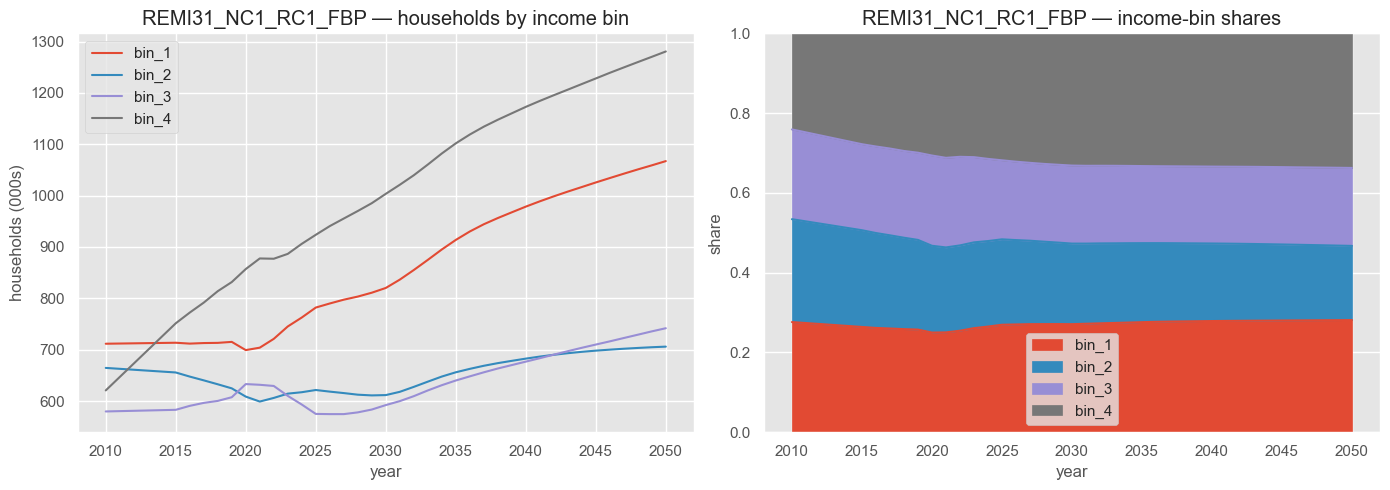

In [22]:
# Reference scenario: income-bin shares over time
ref = outputcontainer[REFERENCE_SCENARIO]
ref_shares = ref.div(ref.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ref.divide(1e3).plot(ax=axes[0])
axes[0].set(title='%s — households by income bin' % REFERENCE_SCENARIO,
            xlabel='year', ylabel='households (000s)')
ref_shares.plot.area(ax=axes[1], stacked=True)
axes[1].set(title='%s — income-bin shares' % REFERENCE_SCENARIO,
            xlabel='year', ylabel='share', ylim=(0, 1))
fig.tight_layout()
plt.show()

### Counterfactual: isolating the income-mix effect from household growth

Each scenario's projected income distribution reflects **two** moving parts: (1) the
regression-driven shift in the *mix* of households across income bins, and (2) the change in
the *total number* of households (which differs by scenario because each reads its own
household projection). Looking at the counts alone, you can't tell how much of a scenario's
income story comes from "different people" versus "more people".

The **counterfactual** holds household growth fixed: it applies every scenario's predicted
income *shares* to the **reference scenario's** total-household trajectory
(`projhh_reference`) instead of that scenario's own. So the only thing that varies across
counterfactual scenarios is the income model's compositional signal — the growth channel is
switched off.

**Why it's useful**

- **Attribution** — comparing *regular* vs. *counterfactual* bars shows how much of the
  cross-scenario spread is driven by the income model itself versus by differing household
  totals.
- **Model diagnostics** — if the counterfactual scenarios look nearly identical, the income
  regressions are barely differentiating the futures, and most of the visible difference is
  just household growth.
- **Fair comparison** — puts every scenario on the same household base, so the income-mix
  effect can be read cleanly without the total-size effect confounding it.

The chart below contrasts the two for `compare_year`: left = regular (each scenario's own
households), right = counterfactual (all on the reference scenario's households).


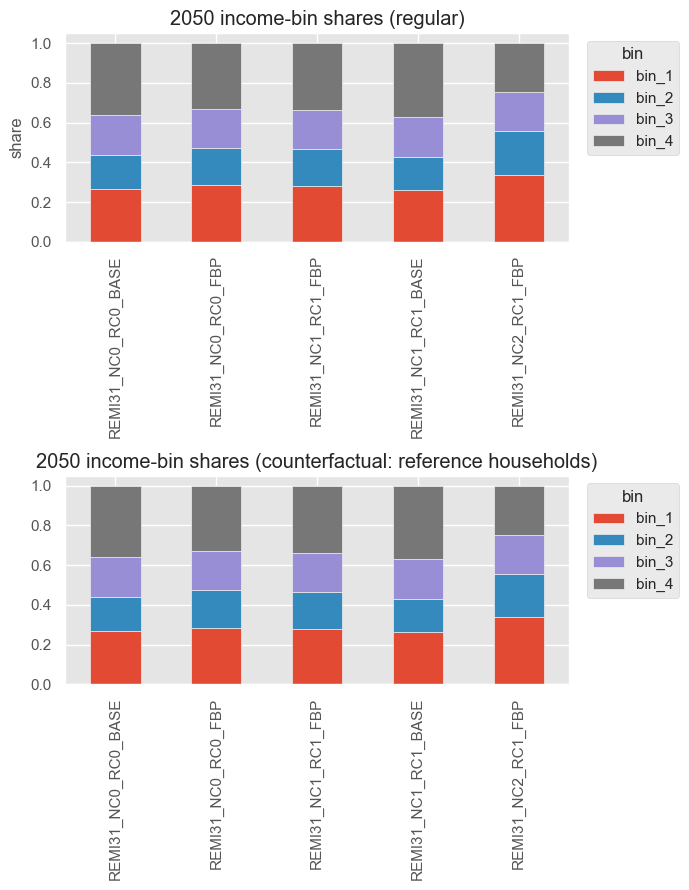

In [66]:
# Regular vs. counterfactual shares in 2050 — isolates the income-model effect
compare_year = 2050
reg = pd.concat({s: v.loc[compare_year] for s, v in outputcontainer.items()}, axis=1)
cf  = pd.concat({s: v.loc[compare_year] for s, v in counterfactuals.items()}, axis=1)

reg_shares = reg.div(reg.sum())
cf_shares  = cf.div(cf.sum())

fig, axes = plt.subplots(2, 1, figsize=(7, 9), sharey=True)
reg_shares.T.plot.bar(ax=axes[0], stacked=True)
axes[0].set(title='%d income-bin shares (regular)' % compare_year, ylabel='share')
cf_shares.T.plot.bar(ax=axes[1], stacked=True)
axes[1].set(title='%d income-bin shares (counterfactual: reference households)' % compare_year)
for ax in axes:
    ax.legend(title='bin', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()